<a href="https://colab.research.google.com/github/SnehaGupta359/first-demo/blob/main/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [6]:
df = pd.read_csv(
    "/content/house_prices.csv.zip",
    compression="zip"
)

print(df.head())
print(df.shape)
print(df.info())

   Index                                              Title  \
0      0  1 BHK Ready to Occupy Flat for sale in Srushti...   
1      1  2 BHK Ready to Occupy Flat for sale in Dosti V...   
2      2  2 BHK Ready to Occupy Flat for sale in Sunrise...   
3      3        1 BHK Ready to Occupy Flat for sale Kasheli   
4      4  2 BHK Ready to Occupy Flat for sale in TenX Ha...   

                                         Description Amount(in rupees)  \
0  Bhiwandi, Thane has an attractive 1 BHK Flat f...           42 Lac    
1  One can find this stunning 2 BHK flat for sale...           98 Lac    
2  Up for immediate sale is a 2 BHK apartment in ...          1.40 Cr    
3  This beautiful 1 BHK Flat is available for sal...           25 Lac    
4  This lovely 2 BHK Flat in Pokhran Road, Thane ...          1.60 Cr    

   Price (in rupees) location Carpet Area         Status         Floor  \
0             6000.0    thane    500 sqft  Ready to Move  10 out of 11   
1            13799.0    than

In [7]:
def convert_price(value):

    value = str(value).lower().replace(",", "").strip()

    match = re.search(
        r'(\d+(?:\.\d+)?)\s*(cr|crore|lac|lakh|l)\b',
        value
    )

    if match:
        number = float(match.group(1))
        unit = match.group(2)

        if unit in ['cr', 'crore']:
            return number * 10000000

        else:
            return number * 100000

    return np.nan


df['Amount(in rupees)'] = df[
    'Amount(in rupees)'
].apply(convert_price)

print(df['Amount(in rupees)'].head())

0     4200000.0
1     9800000.0
2    14000000.0
3     2500000.0
4    16000000.0
Name: Amount(in rupees), dtype: float64


In [8]:
def convert_area(value):

    if pd.isna(value):
        return np.nan

    value = str(value).lower().replace(",", "")

    match = re.search(r'(\d+(?:\.\d+)?)', value)

    if match:
        return float(match.group(1))

    return np.nan


df['Carpet Area'] = df['Carpet Area'].apply(convert_area)

df['Super Area'] = df['Super Area'].apply(convert_area)

# Combine both area columns
df['Area'] = df['Carpet Area'].fillna(df['Super Area'])

In [9]:
for col in ['Bathroom', 'Balcony']:

    df[col] = pd.to_numeric(
        df[col].astype(str).str.extract(r'(\d+)')[0],
        errors='coerce'
    )

In [10]:
features = [
    'location',
    'Area',
    'Bathroom',
    'Balcony',
    'Furnishing',
    'Transaction',
    'Status'
]

X = df[features]

y = df['Amount(in rupees)']

In [11]:
data = df[df['Amount(in rupees)'].notna()].copy()

upper_limit = data['Amount(in rupees)'].quantile(0.99)

data = data[
    data['Amount(in rupees)'] <= upper_limit
]

X = data[features]
y = data['Amount(in rupees)']

print("Dataset shape:", data.shape)

Dataset shape: (176665, 22)


In [12]:
numerical_features = [
    'Area',
    'Bathroom',
    'Balcony'
]

categorical_features = [
    'location',
    'Furnishing',
    'Transaction',
    'Status'
]

preprocessor = ColumnTransformer(
    transformers=[

        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_features),

        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)

    ]
)

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (141332, 7)
Testing data: (35333, 7)


In [14]:
model = Pipeline([

    ('preprocessor', preprocessor),

    ('regressor', LinearRegression())

])

# Train model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [15]:
y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.head())

print("\nPredicted Prices:")
print(y_pred[:5])

Actual Prices:
112055     2500000.0
89188     15500000.0
98134     19200000.0
179236     6500000.0
174185    11700000.0
Name: Amount(in rupees), dtype: float64

Predicted Prices:
[ 7585899.3086132   3171247.45719259 16787975.85001433 11381852.54015217
 15052845.73595505]


In [16]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("R2 Score:", r2)

Mean Absolute Error: 4584220.9402764775
Mean Squared Error: 46573389645029.07
Root Mean Squared Error: 6824469.91677955
R2 Score: 0.5643102391036802


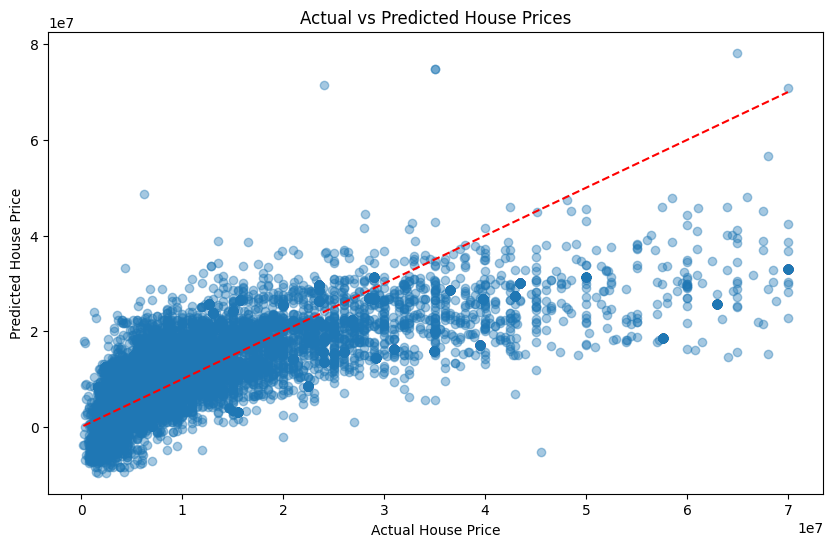

In [17]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.title("Actual vs Predicted House Prices")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

In [18]:
new_house = pd.DataFrame({

    'location': ['thane'],

    'Area': [800],

    'Bathroom': [2],

    'Balcony': [1],

    'Furnishing': ['Semi-Furnished'],

    'Transaction': ['Resale'],

    'Status': ['Ready to Move']

})

predicted_price = model.predict(new_house)

print(
    "Predicted House Price: ₹",
    round(predicted_price[0], 2)
)

Predicted House Price: ₹ 10365339.61
